# PS- 1B: FNN for Fashion MNIST Classification

Open this notebook with `PS- 1B` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, and matplotlib installed. Both datasets are loaded from this folder only.


In [11]:
# a. Import the necessary packages
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD


In [12]:
# b. Load the training and testing data
train = pd.read_csv("fashion-mnist_train.csv")
test = pd.read_csv("fashion-mnist_test.csv")

# First column = label; remaining 784 columns = flattened image pixels.
x_train = train.iloc[:, 1:].values.astype("float32") / 255.0
y_train = train.iloc[:, 0].values
x_test = test.iloc[:, 1:].values.astype("float32") / 255.0
y_test = test.iloc[:, 0].values


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = y_train[:10]
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [13]:
# c. Define the network architecture using Keras
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# d. Train the model using SGD
model.compile(optimizer=SGD(learning_rate=0.01),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=11, batch_size=32, verbose=2)


Epoch 1/11
1875/1875 - 12s - 6ms/step - accuracy: 0.7551 - loss: 0.7380
Epoch 2/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8263 - loss: 0.4960
Epoch 3/11
1875/1875 - 9s - 5ms/step - accuracy: 0.8413 - loss: 0.4522
Epoch 4/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8513 - loss: 0.4246
Epoch 5/11
1875/1875 - 11s - 6ms/step - accuracy: 0.8562 - loss: 0.4053
Epoch 6/11
1875/1875 - 11s - 6ms/step - accuracy: 0.8625 - loss: 0.3901
Epoch 7/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8663 - loss: 0.3770
Epoch 8/11
1875/1875 - 9s - 5ms/step - accuracy: 0.8710 - loss: 0.3651
Epoch 9/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8743 - loss: 0.3545
Epoch 10/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8769 - loss: 0.3458
Epoch 11/11
1875/1875 - 10s - 5ms/step - accuracy: 0.8792 - loss: 0.3370


In [15]:
# e. Evaluate the network on the testing data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")


Test loss: 0.3477
Test accuracy: 87.86%


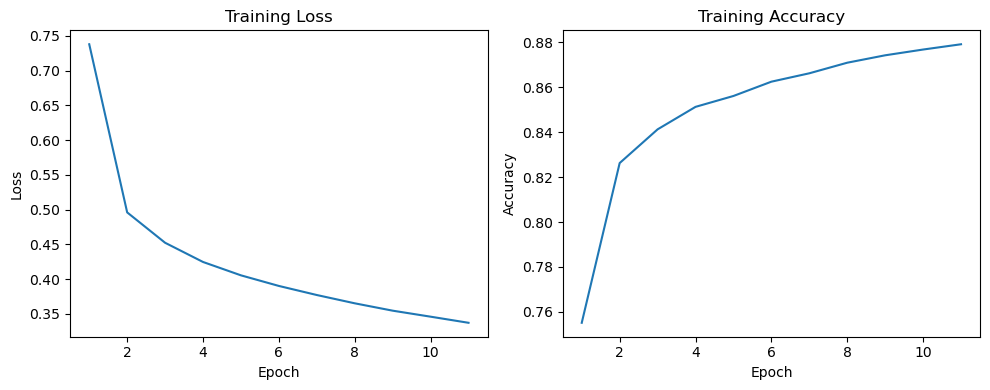

In [16]:
# f. Plot the training loss and accuracy
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()
